/tmp/ipykernel_152443/1901943164.py:141: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap(CMAP_NAME)
/tmp/ipykernel_152443/1901943164.py:213: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


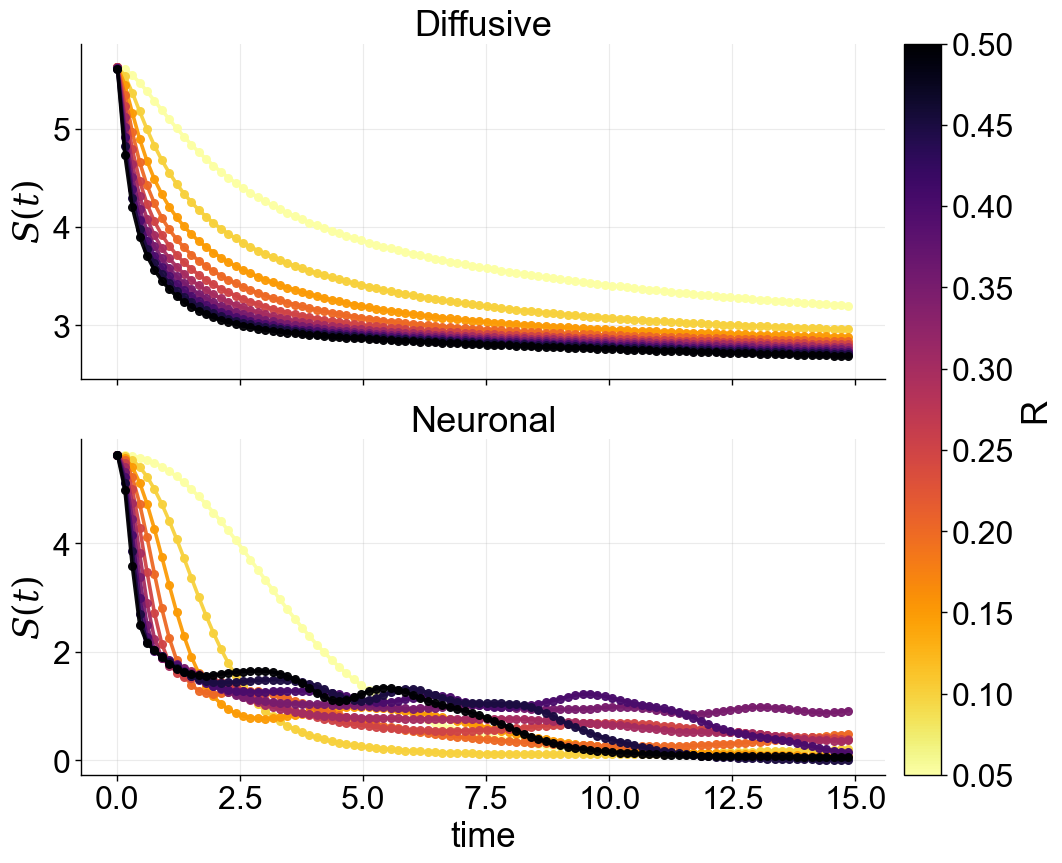

Saved: figs_entropy/S_vs_time_one_realization_across_R_diffusive_and_neuronal.pdf

Chosen realization indices per R (None means no fully-finite series):
Diffusive:
  R=0.0500 -> idx=1
  R=0.1000 -> idx=1
  R=0.1500 -> idx=1
  R=0.2000 -> idx=1
  R=0.2500 -> idx=1
  R=0.3000 -> idx=1
  R=0.3500 -> idx=1
  R=0.4000 -> idx=1
  R=0.4500 -> idx=1
  R=0.5000 -> idx=1
Neuronal
  R=0.0500 -> idx=1
  R=0.1000 -> idx=1
  R=0.1500 -> idx=1
  R=0.2000 -> idx=1
  R=0.2500 -> idx=1
  R=0.3000 -> idx=1
  R=0.3500 -> idx=1
  R=0.4000 -> idx=1
  R=0.4500 -> idx=1
  R=0.5000 -> idx=1


In [1]:
import os
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.cm import get_cmap, ScalarMappable
from matplotlib.colors import Normalize

# ============================================================
# Style: Arial text + DejaVu Serif math
# Default fontsize = 25
# ============================================================
FONT_SIZE = 25

mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": FONT_SIZE,

    "axes.titlesize": FONT_SIZE + 1,
    "axes.labelsize": FONT_SIZE,
    "axes.linewidth": 1.0,

    "xtick.labelsize": FONT_SIZE - 2,
    "ytick.labelsize": FONT_SIZE - 2,
    "xtick.major.width": 1.0,
    "ytick.major.width": 1.0,
    "xtick.major.size": 4,
    "ytick.major.size": 4,

    "legend.fontsize": FONT_SIZE - 2,
    "legend.frameon": False,

    # math (avoid ⟨⟩ glyph issues)
    "mathtext.fontset": "dejavuserif",
    "mathtext.rm": "DejaVu Serif",
    "mathtext.it": "DejaVu Serif:italic",
    "mathtext.bf": "DejaVu Serif:bold",

    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

# ============================================================
# Inputs
# ============================================================
files = [
    "entropy_neuronal_vs_diffusive_ensemble.npz",
    "entropy_neuronal_vs_diffusive_ensemble1.npz",
]

OUTDIR = "figs_entropy"
os.makedirs(OUTDIR, exist_ok=True)

# Choose ONE realization index to try for every R
# (if it's not finite for a given R, we auto-pick the first finite one)
REALIZATION_INDEX = 1

# Make points visible on lines
LW = 2.6
MS = 5.5
MARK_EVERY = 1
ALPHA_LINE = 0.95

# Light colors for LOW R, dark for HIGH R
CMAP_NAME = "inferno_r"

# If too crowded, set to 2 or 3 to plot fewer R curves
R_STRIDE = 1

# ============================================================
# Load + merge helper
# ============================================================
def load_and_merge(files):
    R_all = []
    taus_samp_ref = None
    S_neur_all = []
    S_diff_all = []

    for f in files:
        d = np.load(f, allow_pickle=True)

        R = np.array(d["R_grid"], dtype=float)
        R_all.append(R)

        taus_samp = d["taus_samp"] if "taus_samp" in d.files else None
        if taus_samp is None:
            raise ValueError(f"'taus_samp' not found in {f}")

        if taus_samp_ref is None:
            taus_samp_ref = taus_samp
        else:
            if len(taus_samp) != len(taus_samp_ref) or np.max(np.abs(taus_samp - taus_samp_ref)) > 1e-10:
                raise ValueError("taus_samp differs between files; cannot merge safely.")

        S_neur_all.append(d["S_neur"])  # (n_R, z, n_samp)
        S_diff_all.append(d["S_diff"])

    R_all = np.concatenate(R_all)
    S_neur_all = np.concatenate(S_neur_all, axis=0)
    S_diff_all = np.concatenate(S_diff_all, axis=0)

    idx = np.argsort(R_all)
    return R_all[idx], taus_samp_ref, S_neur_all[idx], S_diff_all[idx]

R_grid, taus_samp, S_neur, S_diff = load_and_merge(files)

# ============================================================
# Pick ONE realization per R (prefer same index, else first valid)
# ============================================================
def pick_realization_series(S_block, prefer_idx=0):
    """
    S_block: (z, n_samp)
    Returns (series, chosen_idx) or (None, None) if no fully-finite series.
    """
    z = S_block.shape[0]
    if 0 <= prefer_idx < z:
        s = S_block[prefer_idx]
        if np.all(np.isfinite(s)):
            return s, prefer_idx
    for j in range(z):
        s = S_block[j]
        if np.all(np.isfinite(s)):
            return s, j
    return None, None

def build_series(S_all, prefer_idx):
    series = []
    chosen = []
    for r_idx in range(len(R_grid)):
        s, j = pick_realization_series(S_all[r_idx], prefer_idx=prefer_idx)
        series.append(s)
        chosen.append(j)
    return series, chosen

series_neur, chosen_idx_neur = build_series(S_neur, REALIZATION_INDEX)
series_diff, chosen_idx_diff = build_series(S_diff, REALIZATION_INDEX)

# ============================================================
# Colormap mapping R -> color (light for low R)
# ============================================================
cmap = get_cmap(CMAP_NAME)
norm = Normalize(vmin=float(np.min(R_grid)), vmax=float(np.max(R_grid)))
sm = ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

# ============================================================
# Build a single figure with two aligned panels
#   - top: Diffusive (natural y-scale)
#   - bottom: Neuronal (natural y-scale)
#   - share x only
#   - only bottom has xlabel "time"
#   - single colorbar for both
# ============================================================
fig, (ax_top, ax_bot) = plt.subplots(
    2, 1,
    figsize=(12.5, 9.5),
    sharex=True,
    sharey=False,               # <-- IMPORTANT: do NOT share y
    gridspec_kw={"hspace": 0.18},
)

# ---- TOP: Diffusive
for r_idx, R in enumerate(R_grid):
    if r_idx % R_STRIDE != 0:
        continue
    s = series_diff[r_idx]
    if s is None:
        continue
    col = cmap(norm(R))
    ax_top.plot(
        taus_samp, s,
        lw=LW, marker="o", ms=MS,
        markevery=MARK_EVERY,
        alpha=ALPHA_LINE,
        color=col,
    )

ax_top.set_ylabel(r"$S(t)$")
ax_top.set_title("Diffusive")
ax_top.grid(True, alpha=0.25)
ax_top.spines["top"].set_visible(False)
ax_top.spines["right"].set_visible(False)
ax_top.tick_params(labelbottom=False)
ax_top.margins(y=0.08)  # small vertical padding (optional but nice)

# ---- BOTTOM: Neuronal
for r_idx, R in enumerate(R_grid):
    if r_idx % R_STRIDE != 0:
        continue
    s = series_neur[r_idx]
    if s is None:
        continue
    col = cmap(norm(R))
    ax_bot.plot(
        taus_samp, s,
        lw=LW, marker="o", ms=MS,
        markevery=MARK_EVERY,
        alpha=ALPHA_LINE,
        color=col,
    )

ax_bot.set_xlabel("time")
ax_bot.set_ylabel(r"$S(t)$")
ax_bot.set_title("Neuronal")
ax_bot.grid(True, alpha=0.25)
ax_bot.spines["top"].set_visible(False)
ax_bot.spines["right"].set_visible(False)

# ---- Single colorbar (one "legend" for R) for the whole figure
cbar = fig.colorbar(sm, ax=[ax_top, ax_bot], orientation="vertical", pad=0.02)
cbar.set_label("R")

fig.tight_layout()
pdf_out = os.path.join(OUTDIR, "S_vs_time_one_realization_across_R_diffusive_and_neuronal.pdf")
fig.savefig(pdf_out, bbox_inches="tight")
plt.show()
print("Saved:", pdf_out)

# ============================================================
# Optional: print which realization indices were used
# ============================================================
print("\nChosen realization indices per R (None means no fully-finite series):")
print("Diffusive:")
for R, j in zip(R_grid, chosen_idx_diff):
    print(f"  R={R:.4f} -> idx={j}")

print("Neuronal")
for R, j in zip(R_grid, chosen_idx_neur):
    print(f"  R={R:.4f} -> idx={j}")


